# Treino do nano GPT (30M) — Colab + VS Code


In [2]:
import os
print(os.getcwd())
print(os.listdir("."))

/content
['.config', 'sample_data']


# 1. Get the Model and Loader

In [3]:
# Célula de bootstrap (sem Git): recria os arquivos do projeto na VM do Colab.
# Rode UMA vez por sessão, antes do resto do notebook. A VM é efêmera: se o runtime reiniciar, rode de novo.
import os

FILES = {}
FILES['model/model.py'] = r'''import math
import torch
import torch.nn as nn
import torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'


def precompute_rope(head_dim, max_seq_len, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))  # [hd/2]
    pos = torch.arange(max_seq_len).float()
    freqs = torch.outer(pos, inv_freq)            # [T, hd/2]
    emb = torch.cat((freqs, freqs), dim=-1)       # [T, hd]
    return emb.cos(), emb.sin()


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)


def apply_rope(x, cos, sin):
    # x: [B, H, T, hd] | cos, sin: [T, hd] (broadcast)
    cos, sin = cos.to(x.dtype), sin.to(x.dtype)
    return x * cos + rotate_half(x) * sin


class Attention(nn.Module):
    """Atenção causal com GQA (n_kv_heads < n_heads), QK-Norm e RoPE.

    n_kv_heads=None  -> MHA (n_kv_heads = n_heads)
    n_kv_heads=1     -> MQA
    """

    def __init__(self, d_model, n_heads, n_kv_heads=None):
        super().__init__()
        n_kv_heads = n_kv_heads or n_heads
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        assert n_heads % n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
        self.head_dim = d_model // n_heads
        assert self.head_dim % 2 == 0, "head_dim must be even for RoPE"

        self.d_model = d_model
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads

        self.wQ = nn.Linear(d_model, n_heads * self.head_dim)
        self.wK = nn.Linear(d_model, n_kv_heads * self.head_dim)
        self.wV = nn.Linear(d_model, n_kv_heads * self.head_dim)
        self.wO = nn.Linear(n_heads * self.head_dim, d_model)

        self.rms_norm_attn_q = nn.RMSNorm(self.head_dim, eps=1e-6, elementwise_affine=True)
        self.rms_norm_attn_k = nn.RMSNorm(self.head_dim, eps=1e-6, elementwise_affine=True)

    def forward(self, x, cos, sin, cache=None):
        b, t, d = x.shape

        # Q: [B, H, T, hd] | K, V: [B, H_kv, T, hd]
        Q = self.wQ(x).reshape(b, t, self.n_heads, self.head_dim).transpose(1, 2)
        K = self.wK(x).reshape(b, t, self.n_kv_heads, self.head_dim).transpose(1, 2)
        V = self.wV(x).reshape(b, t, self.n_kv_heads, self.head_dim).transpose(1, 2)

        # QK-Norm (antes do RoPE)
        Q = self.rms_norm_attn_q(Q)
        K = self.rms_norm_attn_k(K)

        # RoPE em Q e K (o cache guarda K já rotacionado, com H_kv cabeças)
        Q = apply_rope(Q, cos, sin)
        K = apply_rope(K, cos, sin)

        if cache is not None:
            assert t == 1, "com cache, só decode de 1 token por vez"
            K = torch.cat((cache[0], K), dim=2)
            V = torch.cat((cache[1], V), dim=2)
            out = F.scaled_dot_product_attention(Q, K, V, enable_gqa=True)
        else:
            out = F.scaled_dot_product_attention(Q, K, V, is_causal=True, enable_gqa=True)
        new_cache = (K, V)

        out = out.transpose(1, 2).reshape(b, t, self.n_heads * self.head_dim)
        return self.wO(out), new_cache


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads=None, dropout=0.05):
        super().__init__()
        self.attention = Attention(d_model, n_heads, n_kv_heads)
        self.feedforward = nn.Sequential(
            nn.Linear(d_model, d_model * 4),   # 0 (up-projection)
            nn.Dropout(dropout),               # 1
            nn.GELU(),                         # 2
            nn.Linear(d_model * 4, d_model),   # 3 (down-projection)
            nn.Dropout(dropout),               # 4
        )
        self.rms_norm_attn_in = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.rms_norm_attn_out = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.rms_norm_ffn_in = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.rms_norm_ffn_out = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)

    def forward(self, x, cos, sin, cache=None):
        # Pre-norm + post-norm em attn/FFN (estilo Gemma 2)
        attn_out, cache = self.attention(self.rms_norm_attn_in(x), cos, sin, cache)
        x = x + self.rms_norm_attn_out(attn_out)
        x = x + self.rms_norm_ffn_out(self.feedforward(self.rms_norm_ffn_in(x)))
        return x, cache


class GPT(nn.Module):
    def __init__(self, vocab_size, max_seq_len, d_model, n_blocks, n_heads,
                 dropout, n_kv_heads=None):
        super().__init__()
        self.max_seq_len = max_seq_len

        # 1. Embedding (sem pos_emb: a posição vem do RoPE)
        self.embedding = nn.Embedding(vocab_size, d_model)

        # 2. RoPE: tabelas pré-calculadas (não entram no state_dict)
        cos, sin = precompute_rope(d_model // n_heads, max_seq_len)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        # 3. Blocos
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_heads, dropout)
            for _ in range(n_blocks)
        ])

        # 4. Head
        self.norm_final = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.embedding.weight  # weight tying

        # 5. Inicialização de pesos
        self.apply(self.init_weights)
        std = 0.02 / math.sqrt(2 * n_blocks)
        for block in self.blocks:
            nn.init.normal_(block.attention.wO.weight, mean=0.0, std=std)
            nn.init.normal_(block.feedforward[3].weight, mean=0.0, std=std)

    @staticmethod
    def init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, caches=None):
        t = idx.size(1)
        offset = 0 if caches is None else caches[0][0].size(2)
        assert offset + t <= self.max_seq_len, "sequência maior que max_seq_len"

        cos = self.rope_cos[offset:offset + t]
        sin = self.rope_sin[offset:offset + t]

        x = self.embedding(idx)

        new_caches = []
        for i, block in enumerate(self.blocks):
            x, c = block(x, cos, sin, None if caches is None else caches[i])
            new_caches.append(c)

        return self.head(self.norm_final(x)), new_caches


if __name__ == "__main__":
    VOCAB = 49152

    model = GPT(
        vocab_size=VOCAB,
        max_seq_len=512,
        d_model=384,
        n_blocks=6,
        n_heads=6,
        n_kv_heads=2,      # 3 cabeças de Q por par K/V; precisa dividir n_heads
        dropout=0.15,
    ).to(device)

    print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parâmetros")

    # Teste: decode com KV cache == forward completo
    model.eval()
    idx = torch.randint(0, VOCAB, (1, 16), device=device)
    with torch.no_grad():
        full, _ = model(idx)
        _, caches = model(idx[:, :-1])
        step, _ = model(idx[:, -1:], caches)
    print(torch.allclose(full[:, -1], step[:, 0], atol=1e-4))   # True
    print(caches[0][0].shape)   # [1, 2, 15, 64]
'''

FILES['dataset_loader/loader.py'] = r'''"""Loader em streaming para o gigaverbo-v2-synth.

Fluxo:
    1) find_max_batch_size(model, ...)   -> maior micro-batch que cabe na GPU
    2) build_loaders(batch_size)         -> train (80%), val (10%), test (10%), tokenizer
    3) benchmark_loader(train_loader)    -> confere se o loader alimenta a GPU
    4) to_device(batch, device)          -> move (x, y) para a GPU como int64
"""
import gc
import os
import time
import zlib

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import IterableDataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer

os.environ["TOKENIZERS_PARALLELISM"] = "false"  # paralelismo é feito pelos workers

DATASET = "Polygl0t/gigaverbo-v2-synth"
TOKENIZER = "Polygl0t/Tucano2-0.6B-Base"
RANGES = {"train": (0, 80), "val": (80, 90), "test": (90, 100)}  # buckets de 0 a 99


def bucket(doc_id, salt="split-v1"):
    """Bucket determinístico (0-99) a partir do id do documento."""
    return zlib.crc32(f"{salt}:{doc_id}".encode()) % 100


# --------------------------------------------------------------------------- #
# Dataset: streaming + split por hash + tokenização + packing
# --------------------------------------------------------------------------- #
class PackedStream(IterableDataset):
    """Cada item é um batch pronto (x, y) com shape [batch_size, seq_len] (int32),
    onde y é x deslocado em 1 token. Documentos são separados por EOS."""

    def __init__(self, split, seq_len, batch_size, tokenizer,
                 shuffle_buffer=0, seed=42, tok_batch=256):
        self.split, self.L, self.B = split, seq_len, batch_size
        self.tok = tokenizer
        self.eos = np.array([tokenizer.eos_token_id], dtype=np.int32)
        self.shuffle_buffer, self.seed, self.tok_batch = shuffle_buffer, seed, tok_batch

    def __iter__(self):
        lo, hi = RANGES[self.split]
        ds = load_dataset(DATASET, split="train", streaming=True)
        ds = ds.select_columns(["id", "text"])
        if self.shuffle_buffer:
            ds = ds.shuffle(seed=self.seed, buffer_size=self.shuffle_buffer)
        # a divisão de shards entre os workers do DataLoader é feita pelo próprio HF

        L, B = self.L, self.B
        need = B * L + 1
        chunks, total, texts = [], 0, []

        for ex in ds:
            if not (lo <= bucket(ex["id"]) < hi):   # filtra ANTES de tokenizar
                continue
            texts.append(ex["text"])
            if len(texts) < self.tok_batch:
                continue

            ids = self.tok(texts, add_special_tokens=False,
                           return_attention_mask=False)["input_ids"]
            texts = []
            for t in ids:
                a = np.asarray(t, dtype=np.int32)
                chunks += [a, self.eos]
                total += len(a) + 1

            if total >= need:
                arr = np.concatenate(chunks)
                while len(arr) >= need:
                    x = torch.from_numpy(arr[:B * L].reshape(B, L).copy())
                    y = torch.from_numpy(arr[1:B * L + 1].reshape(B, L).copy())
                    yield x, y
                    arr = arr[B * L:]
                chunks, total = [arr], len(arr)
        # a sobra final (menos de um batch) é descartada


class CachedEval:
    """Lê n_batches do loader (streaming) na 1ª iteração e reaproveita da RAM nas
    seguintes. Evita re-varrer o dataset a cada avaliação e deixa a val comparável."""

    def __init__(self, loader, n_batches):
        self.loader, self.n, self._cache = loader, n_batches, None

    def __iter__(self):
        if self._cache is None:
            cache = []
            for batch in self.loader:
                cache.append(batch)
                if len(cache) >= self.n:
                    break
            self._cache = cache
        return iter(self._cache)

    def __len__(self):
        return self.n if self._cache is None else len(self._cache)


def build_loaders(batch_size, seq_len=512, train_workers=None, eval_workers=2,
                  val_tokens=10_000_000, test_tokens=None,
                  shuffle_buffer=10_000, seed=42, tok_batch=256, prefetch_factor=8):
    """Retorna (train_loader, val_loader, test_loader, tokenizer).

    train: 80% dos documentos, streaming infinito-ish com shuffle.
    val:   10%, fixo em `val_tokens` tokens e cacheado em RAM (comparável entre avaliações).
    test:  10%; por padrão streaming completo. Passe test_tokens=N para fixar e cachear.
    """
    tok = AutoTokenizer.from_pretrained(TOKENIZER)
    tok.model_max_length = 10**9  # evita warning em documentos longos
    assert tok.eos_token_id is not None, "tokenizer sem EOS: defina outro separador"

    n_shards = load_dataset(DATASET, split="train", streaming=True).n_shards
    cpu = os.cpu_count() or 4
    if train_workers is None:
        train_workers = max(1, cpu - 2)          # deixa núcleos para o processo principal
    train_workers = min(train_workers, n_shards)
    eval_workers = min(eval_workers, n_shards)
    print(f"cpus={cpu} | shards={n_shards} | workers train={train_workers} eval={eval_workers} "
          f"| {batch_size * seq_len:,} tokens/batch")

    def mk(split, shuffle, nw, persistent, pin):
        ds = PackedStream(split, seq_len, batch_size, tok,
                          shuffle_buffer=shuffle, seed=seed, tok_batch=tok_batch)
        kw = dict(batch_size=None, num_workers=nw, pin_memory=pin and torch.cuda.is_available())
        if nw > 0:
            kw.update(prefetch_factor=prefetch_factor, persistent_workers=persistent)
        return DataLoader(ds, **kw)

    tokens_per_batch = batch_size * seq_len
    train = mk("train", shuffle_buffer, train_workers, True, True)

    val = CachedEval(mk("val", 0, eval_workers, False, False),
                     max(1, val_tokens // tokens_per_batch))

    test = mk("test", 0, eval_workers, False, False)
    if test_tokens:
        test = CachedEval(test, max(1, test_tokens // tokens_per_batch))

    return train, val, test, tok


def to_device(batch, device):
    x, y = batch
    return x.to(device, non_blocking=True).long(), y.to(device, non_blocking=True).long()


# --------------------------------------------------------------------------- #
# Utilitários para não deixar a GPU ociosa
# --------------------------------------------------------------------------- #
def find_max_batch_size(model, seq_len, vocab_size, start=16, max_bs=1024, safety=0.9):
    """Maior micro-batch que cabe na GPU (passo forward+backward+optimizer em bf16).

    Sobe em potências de 2 até dar OOM e refina por bisseção (passo de 8).
    Usa lr=0, então os pesos do modelo não são alterados.
    """
    assert torch.cuda.is_available(), "precisa de GPU"
    device = next(model.parameters()).device
    was_training = model.training
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=0.0, fused=True)

    def fits(bs):
        ok = True
        x = y = logits = loss = None
        try:
            x = torch.randint(0, vocab_size, (bs, seq_len), device=device)
            y = torch.randint(0, vocab_size, (bs, seq_len), device=device)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x)
                loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
            loss.backward()
            opt.step()
            torch.cuda.synchronize()
        except torch.cuda.OutOfMemoryError:
            ok = False
        del x, y, logits, loss
        opt.zero_grad(set_to_none=True)
        gc.collect()
        torch.cuda.empty_cache()
        return ok

    lo, hi, bs = 0, None, start
    while bs <= max_bs:
        if fits(bs):
            lo, bs = bs, bs * 2
        else:
            hi = bs
            break
    if lo == 0:
        raise RuntimeError(f"start={start} já não cabe na GPU; reduza `start`.")
    if hi is not None:
        while hi - lo > 8:
            mid = (lo + hi) // 2
            if fits(mid):
                lo = mid
            else:
                hi = mid

    del opt
    gc.collect()
    torch.cuda.empty_cache()
    model.train(was_training)
    return max(8, int(lo * safety) // 8 * 8)


def benchmark_gpu(model, batch_size, seq_len, vocab_size, steps=20, warmup=5):
    """Mede quantos tokens/s a GPU consome no passo de treino completo, com dados
    sintéticos (sem loader). Usa lr=0, então os pesos não são alterados.
    Se for usar torch.compile, passe o modelo já compilado (o warmup absorve a compilação)."""
    assert torch.cuda.is_available(), "precisa de GPU"
    device = next(model.parameters()).device
    was_training = model.training
    model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=0.0, fused=True)
    x = torch.randint(0, vocab_size, (batch_size, seq_len), device=device)
    y = torch.randint(0, vocab_size, (batch_size, seq_len), device=device)

    def step():
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, _ = model(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)

    for _ in range(warmup):
        step()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(steps):
        step()
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0

    del opt, x, y
    gc.collect()
    torch.cuda.empty_cache()
    model.train(was_training)

    tps = batch_size * seq_len * steps / dt
    print(f"GPU: {tps / 1e6:.2f}M tokens/s ({steps / dt:.1f} passos/s)")
    return tps


def benchmark_loader(loader, n_batches=50, warmup=5):
    """Mede tokens/s que o loader entrega. Compare com os tokens/s do treino:
    se o loader entregar MENOS, a GPU fica esperando dados."""
    it = iter(loader)
    for _ in range(warmup):
        next(it)
    tokens, t0 = 0, time.perf_counter()
    for _ in range(n_batches):
        x, _ = next(it)
        tokens += x.numel()
    dt = time.perf_counter() - t0
    print(f"loader: {tokens / dt / 1e6:.2f}M tokens/s ({n_batches / dt:.1f} batches/s)")
    return tokens / dt


if __name__ == "__main__":
    train_loader, val_loader, test_loader, tok = build_loaders(
        batch_size=8, seq_len=512, train_workers=0, eval_workers=0, val_tokens=100_000)
    x, y = next(iter(train_loader))
    print(x.shape, y.shape, (x[:, 1:] == y[:, :-1]).all().item())  # [8,512] [8,512] True
    print(tok.decode(x[0][:60].long()))
    print("val batches:", sum(1 for _ in val_loader))
'''

for path, content in FILES.items():
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w") as f:
        f.write(content)
    print("escrito:", path, f"({len(content.splitlines())} linhas)")

for pkg in ("model", "dataset_loader"):
    open(f"{pkg}/__init__.py", "a").close()

print("cwd:", os.getcwd(), "->", sorted(os.listdir(".")))

escrito: model/model.py (190 linhas)
escrito: dataset_loader/loader.py (274 linhas)
cwd: /content -> ['.config', 'dataset_loader', 'model', 'sample_data']


# Global variables

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # antes de usar CUDA

import itertools, json, math, sys, time
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoTokenizer
from google.colab import drive
import os


# acha a raiz do repo (a pasta que contém model/model.py), esteja o notebook em train/ ou na raiz
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "model" / "model.py").exists() and (p / "dataset_loader" / "loader.py").exists()), None)
assert ROOT is not None, ("não achei model/model.py e dataset_loader/loader.py a partir de "
                          f"{Path.cwd()}: na VM do Colab, clone o repositório e faça %cd para dentro dele")
sys.path.insert(0, str(ROOT))
print("raiz do projeto:", ROOT)

from model.model import GPT
from dataset_loader.loader import (build_loaders, find_max_batch_size,
                                   benchmark_gpu, benchmark_loader, to_device)

torch.set_float32_matmul_precision("high")
device = "cuda"

# ----------------------------- configuração -----------------------------
drive.mount('/content/drive')

# 2. Define o caminho dentro do seu Drive e cria a pasta automaticamente
CKPT_DIR = "/content/drive/MyDrive/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"Pasta pronta em: {CKPT_DIR}")
SEQ_LEN = 512
BATCH_SIZE = 48           # None = acha o maior que cabe (ou reaproveita o do resume)
GRAD_ACCUM = 4          # tokens/passo = BATCH_SIZE * GRAD_ACCUM * SEQ_LEN
MAX_STEPS = 50_000          # passos de otimizador (ajuste ao seu orçamento de tokens)

LR, MIN_LR, WARMUP = 6e-4, 6e-5, 1_000
WEIGHT_DECAY, BETAS, GRAD_CLIP = 0.1, (0.9, 0.95), 1.0
COMPILE = False             # torch.compile pode aumentar o throughput; teste depois
SEED = 42

REC_EVERY = 100             # frequência dos pontos da curva de loss
LOG_EVERY = 1_000           # print + validação + atualização do gráfico
CKPT_EVERY = 5_000          # checkpoint (só pesos) + amostras de texto
TEST_BATCHES = 300          # None = test completo (10% do dataset: demora e gasta compute units)
RESUME = True
SAMPLE_PROMPTS = ["O Brasil é um país", "Era uma vez"]
# ------------------------------------------------------------------------

try:
    os.makedirs(CKPT_DIR, exist_ok=True)
except OSError:
    CKPT_DIR = "./checkpoints"
    os.makedirs(CKPT_DIR, exist_ok=True)
RESUME_PATH = f"{CKPT_DIR}/resume.pt"
print("checkpoints em:", os.path.abspath(CKPT_DIR))

Mounted at /content/drive
Pasta pronta em: /content/drive/MyDrive/checkpoints
checkpoints em: /content/drive/MyDrive/checkpoints


# Get some values

In [5]:
torch.manual_seed(SEED)

tok = AutoTokenizer.from_pretrained("Polygl0t/Tucano2-0.6B-Base")
VOCAB = len(tok)

model = GPT(vocab_size=VOCAB, max_seq_len=SEQ_LEN, d_model=384, n_blocks=6,
            n_heads=6, n_kv_heads=2, dropout=0.15).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parâmetros")

# weight decay só em matrizes (dim >= 2); normas e biases ficam sem
decay = [p for p in model.parameters() if p.dim() >= 2]
no_decay = [p for p in model.parameters() if p.dim() < 2]
opt = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=LR, betas=BETAS, fused=True)

# ------------------------------- resume ---------------------------------
history = {"step": [], "loss": [], "gnorm": [], "val_step": [], "val_loss": []}
start_step = 0
if RESUME and os.path.exists(RESUME_PATH):
    state = torch.load(RESUME_PATH, map_location=device, weights_only=False)
    model.load_state_dict(state["model"])
    opt.load_state_dict(state["opt"])
    history, start_step = state["history"], state["step"]
    if BATCH_SIZE is None:
        BATCH_SIZE = state["batch_size"]
    print(f"retomando do passo {start_step:,}")

# --------------------------- batch size e loaders ------------------------
if BATCH_SIZE is None:
    BATCH_SIZE = find_max_batch_size(model, SEQ_LEN, VOCAB)  # lr=0: não altera os pesos

fwd = torch.compile(model) if COMPILE else model
tokens_per_step = BATCH_SIZE * GRAD_ACCUM * SEQ_LEN
print(f"batch {BATCH_SIZE} x accum {GRAD_ACCUM} x {SEQ_LEN} = {tokens_per_step:,} tokens/passo "
      f"| total previsto: {tokens_per_step * MAX_STEPS / 1e9:.2f}B tokens")

# seed muda ao retomar para não repetir exatamente os mesmos dados do início do stream
train_loader, val_loader, test_loader, _ = build_loaders(
    BATCH_SIZE, SEQ_LEN, seed=SEED + start_step)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/8.93k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/6.15M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

28.3M parâmetros
batch 48 x accum 4 x 512 = 98,304 tokens/passo | total previsto: 4.92B tokens


README.md:   0%|          | 0.00/11.8k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/38 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/38 [00:00<?, ?it/s]

cpus=12 | shards=38 | workers train=10 eval=2 | 24,576 tokens/batch


# Define some functions

In [6]:
def get_lr(step):
    """Warmup linear + cosine até MIN_LR."""
    if step < WARMUP:
        return LR * (step + 1) / WARMUP
    if step >= MAX_STEPS:
        return MIN_LR
    t = (step - WARMUP) / max(1, MAX_STEPS - WARMUP)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * t))


def fmt_time(s):
    s = int(s)
    h, r = divmod(s, 3600)
    return f"{h}h{r // 60:02d}m"


def atomic_save(obj, path):
    """Escreve em arquivo temporário e renomeia: uma queda no meio não corrompe o checkpoint."""
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def save_weights(name):
    """Checkpoint SÓ com os pesos do modelo."""
    path = f"{CKPT_DIR}/{name}.pt"
    atomic_save(model.state_dict(), path)
    return path


def save_resume(step):
    """Estado completo (otimizador, passo, histórico) para retomar o treino."""
    atomic_save({"model": model.state_dict(), "opt": opt.state_dict(), "step": step,
                 "history": history, "batch_size": BATCH_SIZE}, RESUME_PATH)


def weights_finite():
    return all(torch.isfinite(p).all().item() for p in model.parameters())


@torch.no_grad()
def evaluate(loader, max_batches=None):
    was_training = model.training
    model.eval()
    total, n = torch.zeros((), device=device), 0
    for batch in itertools.islice(loader, max_batches):
        x, y = to_device(batch, device)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, _ = model(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
        total += loss.float()
        n += 1
    model.train(was_training)
    return (total / max(n, 1)).item()


@torch.no_grad()
def generate(prompt, max_new_tokens=100, temperature=0.8, top_k=50):
    """Amostra de texto usando o KV cache do modelo."""
    was_training = model.training
    model.eval()
    ids = tok(prompt, return_tensors="pt", add_special_tokens=False)["input_ids"].to(device)
    if ids.numel() == 0:
        ids = torch.tensor([[tok.eos_token_id]], device=device)
    ids = ids[:, -(model.max_seq_len - max_new_tokens):]
    out = ids
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, caches = model(ids)
        for _ in range(max_new_tokens):
            l = logits[:, -1].float() / temperature
            if top_k:
                v, _ = torch.topk(l, min(top_k, l.size(-1)))
                l[l < v[:, [-1]]] = -float("inf")
            nxt = torch.multinomial(F.softmax(l, dim=-1), 1)
            out = torch.cat([out, nxt], dim=1)
            if nxt.item() == tok.eos_token_id:
                break
            logits, caches = model(nxt, caches)
    model.train(was_training)
    return tok.decode(out[0].tolist())


class LivePlot:
    """Gráfico que se atualiza no mesmo lugar (sem apagar os prints da célula)."""

    def __init__(self, save_path):
        self.fig, self.ax = plt.subplots(1, 2, figsize=(13, 4))
        plt.close(self.fig)  # evita exibição duplicada
        self.handle = display(self.fig, display_id=True)
        self.save_path = save_path

    def update(self, h):
        a0, a1 = self.ax
        a0.clear()
        a1.clear()
        a0.plot(h["step"], h["loss"], label="train", linewidth=1)
        if h["val_step"]:
            a0.plot(h["val_step"], h["val_loss"], "o-", label="val", markersize=4)
        if len(h["loss"]) > 3:  # ignora o começo (loss ~ ln(V)) para o eixo y ficar legível
            a0.set_ylim(bottom=min(h["loss"] + h["val_loss"]) * 0.95,
                        top=max(h["loss"][3:] + h["val_loss"]) * 1.05)
        a0.set_title("loss")
        a0.set_xlabel("step")
        a0.legend()
        a0.grid(alpha=0.3)
        a1.plot(h["step"], h["gnorm"], linewidth=1)
        a1.set_title("grad norm (antes do clip)")
        a1.set_xlabel("step")
        a1.grid(alpha=0.3)
        self.fig.tight_layout()
        self.handle.update(self.fig)
        self.fig.savefig(self.save_path, dpi=100)


def infinite(loader):
    while True:
        for batch in loader:
            yield batch

In [7]:
# Opcional: o loader entrega tokens mais rápido do que a GPU consome?
gpu_tps = benchmark_gpu(fwd, BATCH_SIZE, SEQ_LEN, VOCAB)
loader_tps = benchmark_loader(train_loader)
print(f"loader / GPU = {loader_tps / gpu_tps:.2f}x  (acima de ~1.2x há folga; abaixo de 1x a GPU espera dados)")

GPU: 0.07M tokens/s (2.9 passos/s)
loader: 0.01M tokens/s (0.5 batches/s)
loader / GPU = 0.19x  (acima de ~1.2x há folga; abaixo de 1x a GPU espera dados)


In [8]:
!nvidia-smi

Tue Nov 17 02:09:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   61C    P0             30W /   72W |     398MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 2. Train Loop

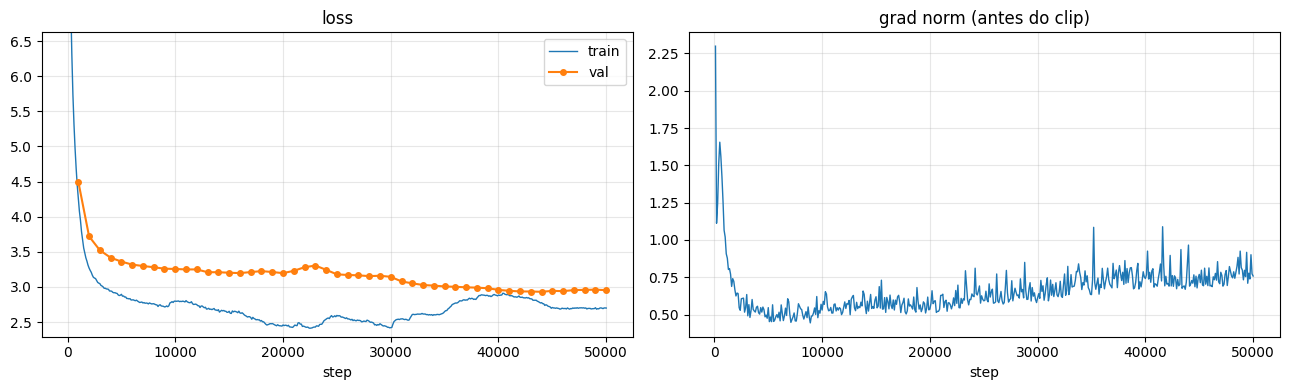

step   1,000/50,000 | loss 6.0835 | val 4.4999 (ppl 90.0) | lr 6.00e-04 | gnorm 1.02 | 64k tok/s | espera dados 7.7% | 18.4 GB | ETA 20h44m
step   2,000/50,000 | loss 3.5888 | val 3.7200 (ppl 41.3) | lr 5.99e-04 | gnorm 0.62 | 70k tok/s | espera dados 0.1% | 18.4 GB | ETA 18h49m
step   3,000/50,000 | loss 3.1250 | val 3.5220 (ppl 33.9) | lr 5.98e-04 | gnorm 0.63 | 70k tok/s | espera dados 0.1% | 18.4 GB | ETA 18h26m
step   4,000/50,000 | loss 2.9787 | val 3.4166 (ppl 30.5) | lr 5.95e-04 | gnorm 0.56 | 70k tok/s | espera dados 0.1% | 18.4 GB | ETA 18h03m
step   5,000/50,000 | loss 2.9054 | val 3.3604 (ppl 28.8) | lr 5.91e-04 | gnorm 0.55 | 70k tok/s | espera dados 0.1% | 18.4 GB | ETA 17h39m
  checkpoint salvo: /content/drive/MyDrive/checkpoints/step_0005000.pt
  >> O Brasil é um país diversificado, vibrante e singular, onde a economia nacional pode parecer um lugar distante, mas há algo a mudar para descobrir.  ## O Sistema Nacional Brasileiro  No Brasil, a economia brasileira vem de f

In [9]:
plot = LivePlot(f"{CKPT_DIR}/loss.png")
if history["step"]:
    plot.update(history)

train_iter = infinite(train_loader)
model.train()
torch.cuda.reset_peak_memory_stats()

loss_acc = torch.zeros((), device=device)
gn_acc = torch.zeros((), device=device)
n_acc = 0
win_start, t_win, t_data = start_step, time.perf_counter(), 0.0
done = start_step

try:
    for step in range(start_step, MAX_STEPS):
        lr = get_lr(step)
        for g in opt.param_groups:
            g["lr"] = lr

        for _ in range(GRAD_ACCUM):
            t0 = time.perf_counter()
            x, y = to_device(next(train_iter), device)
            t_data += time.perf_counter() - t0
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = fwd(x)
                loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1)) / GRAD_ACCUM
            loss.backward()
            loss_acc += loss.detach()

        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        opt.step()
        opt.zero_grad(set_to_none=True)
        gn_acc += gnorm.detach()
        n_acc += 1
        done = step + 1

        # ---- amostra da loss (único ponto de sincronização com a GPU) ----
        if done % REC_EVERY == 0:
            l, g = loss_acc.item() / n_acc, gn_acc.item() / n_acc
            if not (math.isfinite(l) and math.isfinite(g)):
                raise FloatingPointError(f"loss/grad norm não finitos no passo {done}")
            history["step"].append(done)
            history["loss"].append(l)
            history["gnorm"].append(g)
            loss_acc.zero_()
            gn_acc.zero_()
            n_acc = 0

        # ---- a cada LOG_EVERY: print, validação, gráfico ----
        if done % LOG_EVERY == 0:
            dt = time.perf_counter() - t_win
            n_steps = done - win_start
            n_rec = max(1, min(len(history["loss"]), LOG_EVERY // REC_EVERY))
            loss_w = sum(history["loss"][-n_rec:]) / n_rec
            tok_s = n_steps * tokens_per_step / dt
            eta = (MAX_STEPS - done) * dt / n_steps

            val = evaluate(val_loader)
            history["val_step"].append(done)
            history["val_loss"].append(val)

            print(f"step {done:>7,}/{MAX_STEPS:,} | loss {loss_w:.4f} | val {val:.4f} "
                  f"(ppl {math.exp(val):.1f}) | lr {lr:.2e} | gnorm {history['gnorm'][-1]:.2f} | "
                  f"{tok_s / 1e3:.0f}k tok/s | espera dados {100 * t_data / dt:.1f}% | "
                  f"{torch.cuda.max_memory_allocated() / 1e9:.1f} GB | ETA {fmt_time(eta)}")
            plot.update(history)
            with open(f"{CKPT_DIR}/history.json", "w") as f:
                json.dump(history, f)

            win_start, t_win, t_data = done, time.perf_counter(), 0.0
            torch.cuda.reset_peak_memory_stats()

        if done % CKPT_EVERY == 0:
            path = save_weights(f"step_{done:07d}")
            save_resume(done)
            print(f"  checkpoint salvo: {path}")
            for prompt in SAMPLE_PROMPTS:
                try:
                    print("  >>", generate(prompt).replace("\n", " "))
                except Exception as e:
                    print("  (amostra falhou:", repr(e), ")")

except BaseException as e:  
    print(f"\n!! interrompido no passo {done:,}: {type(e).__name__}: {e}")
    try:
        if weights_finite():
            print("  pesos salvos em:", save_weights(f"crash_step_{done:07d}"))
            save_resume(done)
            print("  estado de retomada salvo em:", RESUME_PATH)
        else:
            print("  pesos com NaN/inf: nada salvo; use o último checkpoint (step_*.pt / resume.pt)")
    except BaseException as e2:
        print("  não foi possível salvar:", repr(e2))
    raise

print("treino concluído. pesos finais:", save_weights("final"))
save_resume(done)

In [10]:
test_loss = evaluate(test_loader, TEST_BATCHES)
print(f"test loss {test_loss:.4f} | ppl {math.exp(test_loss):.1f}")

test loss 2.9543 | ppl 19.2


# 3. Decoding 

In [35]:
import torch

def top_k_top_p_filtering(logits, top_k=50, top_p=0.8, filter_value=-float('Inf')):
    """Filtra os logits usando Top-K e/ou Top-P (nucleus sampling)."""
    batch_size = logits.size(0)
    
    # Top-K filtering
    if top_k > 0:
        top_k = min(top_k, logits.size(-1))
        values, _ = torch.topk(logits, top_k)
        min_values = values[:, -1].unsqueeze(-1)
        logits = torch.where(logits < min_values, torch.tensor(filter_value, device=logits.device, dtype=logits.dtype), logits)

    # Top-P filtering (Nucleus)
    if top_p > 0.0:
        sorted_logits, sorted_indices = torch.sort(logits, descending=True)
        sorted_probs = torch.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        # Remove tokens com probabilidade cumulativa acima do threshold
        sorted_indices_to_remove = cumulative_probs > top_p
        # Desloca para a direita para manter o primeiro token que ultrapassa o limite
        sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
        sorted_indices_to_remove[..., 0] = False

        # Recoloca os valores filtrados no formato original
        for i in range(batch_size):
            indices_to_remove = sorted_indices[i][sorted_indices_to_remove[i]]
            logits[i, indices_to_remove] = filter_value
            
    return logits


@torch.no_grad()
def sample_decode(
    model,
    input_ids,
    max_new_tokens=100,
    eos_token_id=None,
    repetition_penalty=1.6,
    temperature=0.8,
    top_k=50,
    top_p=0.8
):
    model.eval()
    batch_size = input_ids.size(0)

    # 1. PREFILL: processa o prompt inteiro
    logits, caches = model(input_ids)
    next_token_logits = logits[:, -1, :]

    # Aplicar repetition penalty no prefill
    if repetition_penalty != 1.0:
        for i in range(batch_size):
            tokens = input_ids[i].unique()
            scores = next_token_logits[i, tokens]
            next_token_logits[i, tokens] = torch.where(
                scores < 0, scores * repetition_penalty, scores / repetition_penalty
            )

    # Aplicar Temperature
    if temperature > 0:
        next_token_logits = next_token_logits / temperature

    # Aplicar Top-K e Top-P
    next_token_logits = top_k_top_p_filtering(next_token_logits, top_k=top_k, top_p=top_p)

    # Amostragem (Sampling) do primeiro token
    probs = torch.softmax(next_token_logits, dim=-1)
    next_token = torch.multinomial(probs, num_samples=1)
    
    generated = [next_token]

    if eos_token_id is not None:
        finished = next_token.squeeze(-1).eq(eos_token_id)

    # 2. DECODE: processa somente o último token gerado
    for _ in range(max_new_tokens - 1):

        if eos_token_id is not None and finished.all():
            break

        logits, caches = model(
            next_token,
            caches=caches
        )
        next_token_logits = logits[:, -1, :]

        # Aplicar repetition penalty considerando prompt + tokens gerados
        if repetition_penalty != 1.0:
            current_generated = torch.cat(generated, dim=1)
            full_ids = torch.cat([input_ids, current_generated], dim=1)
            
            for i in range(batch_size):
                tokens = full_ids[i].unique()
                scores = next_token_logits[i, tokens]
                next_token_logits[i, tokens] = torch.where(
                    scores < 0, scores * repetition_penalty, scores / repetition_penalty
                )

        # Aplicar Temperature
        if temperature > 0:
            next_token_logits = next_token_logits / temperature

        # Aplicar Top-K e Top-P
        next_token_logits = top_k_top_p_filtering(next_token_logits, top_k=top_k, top_p=top_p)

        # Amostragem
        probs = torch.softmax(next_token_logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        generated.append(next_token)

        if eos_token_id is not None:
            finished |= next_token.squeeze(-1).eq(eos_token_id)

    # 3. CONCATENA PROMPT + TOKENS GERADOS
    generated_tensor = torch.cat(generated, dim=1)

    return torch.cat([input_ids, generated_tensor], dim=1)

In [54]:
def prompts(prompt):
    inputs = tok(
        prompt,
        return_tensors="pt"
    ).to(device)

    output = sample_decode(
        model=model,
        input_ids=inputs["input_ids"],
        max_new_tokens=150,
        eos_token_id=tok.eos_token_id,
        repetition_penalty=1.5,
        temperature=0.8,
        top_k=50,
        top_p=0.8
    )

    print(tok.decode(
        output[0],
        skip_special_tokens=True
    ))

# 4. Prompt Evals

In [56]:
frases = [
    'Conheça Tóquio através das suas histórias',
    'Uma Aventura Científica Durante o Natal',
    'Antes de comprar qualquer coisa online sempre',
    'Depois de encontrar aqueles vendedores legais',
    'Entendendo Como os Computadores Compreendem Nossos Textos'
]


for frase in frases:
    print(f'=' * 50)
    print(f'Starting frase: {frase}')
    print()
    prompts(frase)
    print()
    print()
    print(f'=' * 50)

Starting frase: Conheça Tóquio através das suas histórias

Conheça Tóquio através das suas histórias, personagens e temas.
---


Starting frase: Uma Aventura Científica Durante o Natal

Uma Aventura Científica Durante o Natal
- O Dia de Cães é uma festividade natalina. Ela tem como objetivo criar um universo cheio e emocionante para as crianças do mundo inteiro!

## Um Festival Familiar: O Fantasma da Vida dos Pais
O filme infantil "Fantástico" da vida desses pais foi apresentado em vários eventos familiares que foram divertidos, inclusive no evento escolar da escola pública local. Cada episódio trouxe algo novo à tona sobre a importância desse encontro familiar na nossa sociedade atual - desde os famosos Jogos Olímpicos até nossos dias modernos -, mas agora estamos mais próximos com essa experiência mágica que faz parte deste ano especial: o aniversário das famílias de seus filhos (Gap) ou simplesmente seu pai/mãe.

### Exemplos Práticos 
-


Starting frase: Antes de comprar qualquer 

# Get metrics

In [76]:
import json
import torch
import math

def exportar_relatorio_metricas(
    model, 
    val_loss_final: float, 
    train_loss_final: float = 2.6949,
    total_steps: int = 50000,
    total_tokens_treinados: int = 4900000000, # ~4.9B tokens
    caminho_arquivo: str = "metricas_modelo_30m.json"
):
    # 1. Coleta dados estruturais do modelo
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    # 2. Calcula métricas derivadas
    val_ppl = math.exp(val_loss_final)
    gap_gen = val_loss_final - train_loss_final
    
    # 3. Monta o dicionário estruturado
    relatorio = {
        "arquitetura": {
            "nome_modelo": "GPT-30M-Portuguese",
            "parametros_totais": total_params,
            "parametros_totais_milhoes": round(total_params / 1e6, 2),
            "parametros_treinaveis": trainable_params
        },
        "treinamento": {
            "steps_totais": total_steps,
            "tokens_processados": total_tokens_treinados,
            "tokens_processados_bilhoes": round(total_tokens_treinados / 1e9, 2),
            "batch_size_efetivo": 192, # 48 * 4 (grad_acc)
            "gradient_accumulation_steps": 4,
            "learning_rate_final": 6.0e-5
        },
        "metricas_convergencia": {
            "train_loss": train_loss_final,
            "validation_loss": val_loss_final,
            "validation_perplexity": round(val_ppl, 2),
            "gap_generalizacao": round(gap_gen, 4),
            "status_generalizacao": "Saudável (sem overfitting severo)" if gap_gen < 0.4 else "Atenção"
        },
        "hardware_e_eficiencia": {
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "espera_de_dados_io_pct": 0.1,
            "gradient_norm_final": 0.76
        }
    }
    
    # 4. Salva em arquivo JSON (perto para o GitHub / Portfólio)
    with open(caminho_arquivo, "w", encoding="utf-8") as f:
        json.dump(relatorio, f, indent=4, ensure_ascii=False)
        
    print(f"[Sucesso] Relatório de métricas exportado com sucesso para: {caminho_arquivo}")
    return relatorio

In [77]:
# Supondo que você obteve a validation loss final da sua eval (ex: 2.9537)
dados_metricas = exportar_relatorio_metricas(
    model=model,
    val_loss_final=2.9537,
    train_loss_final=2.6949,
    total_steps=50000,
    caminho_arquivo="eval_results_30m.json"
)

# Visualiza o JSON gerado diretamente no notebook
import pprint
pprint.pprint(dados_metricas)

[Sucesso] Relatório de métricas exportado com sucesso para: eval_results_30m.json
{'arquitetura': {'nome_modelo': 'GPT-30M-Portuguese',
                 'parametros_totais': 28339584,
                 'parametros_totais_milhoes': 28.34,
                 'parametros_treinaveis': 28339584},
 'hardware_e_eficiencia': {'espera_de_dados_io_pct': 0.1,
                           'gpu': 'NVIDIA L4',
                           'gradient_norm_final': 0.76},
 'metricas_convergencia': {'gap_generalizacao': 0.2588,
                           'status_generalizacao': 'Saudável (sem overfitting '
                                                   'severo)',
                           'train_loss': 2.6949,
                           'validation_loss': 2.9537,
                           'validation_perplexity': 19.18},
 'treinamento': {'batch_size_efetivo': 192,
                 'gradient_accumulation_steps': 4,
                 'learning_rate_final': 6e-05,
                 'steps_totais': 50000,
     